# 02 - Fine-tuning `cahya/wav2vec2-large-xlsr-sundanese`

IF4071 Fase II - ASR bahasa Sunda dengan wav2vec 2.0 + CTC.

## A. Description
Notebook ini melakukan supervised fine-tuning berdasarkan penelitian Cahya, yang sudah di-fine-tune untuk ASR bahasa Sunda, dengan data berlabel kami. Tujuannya domain adaptation: dari ujaran baca OpenSLR-44 ke ujaran spontan dengan penutur dan kondisi rekaman yang beragam. Model dilatih dengan CTC loss. Setiap frame (~20 ms) menghasilkan distribusi karakter atau blank token, dan loss menjumlahkan semua alignment yang menghasilkan teks target, sehingga tidak perlu label per frame.

Ujaran spontan bahasa Sunda sulit dikenali: datanya sedikit, penuturnya beragam (penutur asli dan non-asli), ada filler dan disfluency, sebagian rekaman ber-noise, sering terjadi code-switching ke bahasa Indonesia, atau Inggris, dan ejaannya tidak baku.

**Data:** gabungan korpus kami dan korpus kelompok G04, total 21 penutur, dibagi per penutur menjadi 13 train, 4 validation, dan 4 test. Pada metadata G04_S05 sebagian kolom durasi tidak cocok dengan audionya. Panjang transkripsi ternyata mengikuti durasi audio sebenarnya (r = 0,54, sedangkan terhadap durasi metadata r = 0,04), jadi pasangan audio dan teksnya tetap dipakai dengan durasi hasil pengukuran ulang.

**Acuan:** [model card Cahya](https://huggingface.co/cahya/wav2vec2-large-xlsr-sundanese) dan notebook pelatihannya (`XLSR_Wav2Vec2_for_Indonesian_Fine_Tuning-Sundanese.ipynb` di repositori `cahya-wirawan/indonesian-speech-recognition`). Model card tersebut tidak merujuk ke makalah. WER 6,19% milik Cahya diukur pada OpenSLR-44 dengan pembagian acak per ujaran, jadi tidak bisa dibandingkan langsung dengan angka kami.

**Alur:** model dilatih pada train set, checkpoint dipilih dengan validation set, dan hasil dilaporkan pada validation set. Test set tidak dimuat di notebook ini.

## B. Kaggle Environment
Digunakan GPU T4 dan internet On pada notebook ini.

In [1]:
# Ubah sesuai nama dataset Kaggle yang dilampirkan melalui Add Input.
DATASET_ROOT = "/kaggle/input/datasets/peterwongsoredjo/sundanese-asr-corpus"
OUTPUT_ROOT = "/kaggle/working/asr_outputs"  # Folder input Kaggle hanya dapat dibaca
SEED = 42
USE_ALL_GPUS = True  # Isi False untuk memakai satu GPU saja bila pelatihan multi-GPU bermasalah

import importlib.util
import subprocess
import sys
from dataclasses import dataclass
from pathlib import Path
import gc
import inspect
import json
import os
import platform
import random
import time

# Harus diatur sebelum torch memakai CUDA agar GPU kedua benar-benar tersembunyi.
if not USE_ALL_GPUS:
    os.environ["CUDA_VISIBLE_DEVICES"] = "0"

# Kaggle sudah menyertakan torch dan transformers sehingga hanya paket yang belum ada yang dipasang.
missing = [p for p in ("jiwer", "accelerate", "soundfile") if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    print("Terpasang:", missing, "- bila impor gagal, pilih Run > Restart session lalu jalankan ulang.")

from huggingface_hub import model_info
from transformers import EarlyStoppingCallback, Trainer, TrainerCallback
from transformers import TrainingArguments
from transformers import Wav2Vec2CTCTokenizer, Wav2Vec2ForCTC, Wav2Vec2Processor
from transformers.trainer_utils import get_last_checkpoint
import jiwer
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import transformers

if not os.path.isdir(DATASET_ROOT):
    attached = os.listdir("/kaggle/input") if os.path.isdir("/kaggle/input") else []
    raise FileNotFoundError(f"DATASET_ROOT {DATASET_ROOT!r} tidak ditemukan. Input terlampir: {attached}. "
                            "Isi dengan folder yang memuat splits/ dan audio/.")
os.makedirs(OUTPUT_ROOT, exist_ok=True)

Terpasang: ['jiwer'] - bila impor gagal, pilih Run > Restart session lalu jalankan ulang.


## Helper Codes
Semua fungsi pembantu (metrik, data, model, dan training) didefinisikan di bawah, jadi notebook hanya butuh dataset terlampir (`audio/` dan `splits/`).

### Helper: Metrics

In [2]:
def _clean(s) -> str:
    return " ".join(str(s).split())


def fold_diacritics(text: str) -> str:
    """Hanya dipakai untuk metrik sekunder tanpa aksen dan tidak pernah dipakai sebagai target latih."""
    return text.replace("\u00e9", "e")


def compute_error_rates(references, predictions) -> dict:
    """Menghitung WER dan CER sebagai total edit dibagi total unit referensi. Prediksi kosong dihitung sebagai penghapusan penuh."""
    refs, hyps = list(references), [_clean(h) for h in predictions]
    if len(refs) != len(hyps):
        raise ValueError(f"{len(refs)} referensi vs {len(hyps)} prediksi")
    if not refs:
        raise ValueError("Tidak ada ujaran untuk dinilai")
    refs = [_clean(r) for r in refs]
    if any(r == "" for r in refs):
        raise ValueError("Referensi kosong ditemukan; perbaiki manifes")
    wo = jiwer.process_words(refs, hyps)
    co = jiwer.process_characters(refs, hyps)
    return {
        "wer": wo.wer, "cer": co.cer, "n_utterances": len(refs),
        "word_ref_count": wo.hits + wo.substitutions + wo.deletions,
        "char_ref_count": co.hits + co.substitutions + co.deletions,
        "word_sub": wo.substitutions, "word_del": wo.deletions, "word_ins": wo.insertions,
        "char_sub": co.substitutions, "char_del": co.deletions, "char_ins": co.insertions,
    }


def e_acute_report(references, predictions) -> dict:
    """Menghitung kata referensi ber-é yang ditulis persis benar dan huruf é yang diprediksi."""
    refs, hyps = list(references), [_clean(h) for h in predictions]
    out = jiwer.process_words(refs, hyps)
    total = correct = 0
    for ref_words, chunks in zip(out.references, out.alignments):
        total += sum("\u00e9" in w for w in ref_words)
        for c in chunks:
            if c.type == "equal":
                correct += sum("\u00e9" in w for w in ref_words[c.ref_start_idx:c.ref_end_idx])
    return {"e_words_correct": correct, "e_words_total": total,
            "e_word_accuracy": correct / total if total else None,
            "e_chars_predicted": sum(h.count("\u00e9") for h in hyps),
            "e_chars_reference": sum(r.count("\u00e9") for r in refs)}


def evaluate_predictions(references, predictions) -> dict:
    """Metrik utama (ketat), metrik pelengkap tanpa aksen, dan laporan é."""
    strict = compute_error_rates(references, predictions)
    folded = compute_error_rates([fold_diacritics(r) for r in references],
                                 [fold_diacritics(p) for p in predictions])
    return {"wer": strict["wer"], "cer": strict["cer"], "wer_folded": folded["wer"], "cer_folded": folded["cer"],
            "details": strict, **e_acute_report(references, predictions)}

### Helper: Data

In [3]:
def load_audio(path, expected_sr: int = 16000) -> np.ndarray:
    """Memuat gelombang mono float32 tanpa resampling dan menolak format yang tidak sesuai."""
    wav, sr = sf.read(str(path), dtype="float32", always_2d=True)
    if sr != expected_sr:
        raise ValueError(f"{path}: laju sampel {sr} != {expected_sr}")
    if wav.shape[1] != 1:
        raise ValueError(f"{path}: diharapkan mono, ditemukan {wav.shape[1]} kanal")
    if wav.shape[0] == 0:
        raise ValueError(f"{path}: audio kosong")
    return wav[:, 0]


def pad_ctc_labels(label_ids: list, pad_value: int = -100) -> np.ndarray:
    """Posisi padding bernilai -100 agar diabaikan oleh loss CTC."""
    out = np.full((len(label_ids), max(len(x) for x in label_ids)), pad_value, dtype=np.int64)
    for i, ids in enumerate(label_ids):
        out[i, : len(ids)] = ids
    return out


def verify_saved_split(split_dir) -> dict:
    """Memastikan CSV tersimpan konsisten dengan metadata dan tidak ada penutur maupun ujaran yang tumpang tindih."""
    d = Path(split_dir)
    meta = json.loads((d / "split_metadata.json").read_text())
    seen = {}
    for name in ("train", "val", "test"):
        if (d / f"{name}.csv").exists():
            df = pd.read_csv(d / f"{name}.csv")
            if set(df["speaker_id"]) != set(meta["subsets"][name]["speakers"]):
                raise AssertionError(f"Penutur {name}.csv berbeda dari split_metadata.json")
            seen[name] = df
    names = list(seen)
    for i, a in enumerate(names):
        for b in names[i + 1:]:
            if not set(seen[a]["speaker_id"]).isdisjoint(seen[b]["speaker_id"]):
                raise AssertionError(f"Penutur tumpang tindih antara {a} dan {b}")
            if not set(seen[a]["file"]).isdisjoint(seen[b]["file"]):
                raise AssertionError(f"Ujaran tumpang tindih antara {a} dan {b}")
    return meta


def load_split(dataset_root, name: str, check_audio: bool = True) -> pd.DataFrame:
    """Memuat CSV pembagian dan menambahkan `abs_audio_path` relatif terhadap dataset_root."""
    root = Path(dataset_root)
    df = pd.read_csv(root / "splits" / f"{name}.csv")
    df["abs_audio_path"] = df["audio_path"].map(lambda p: str(root / p))
    if check_audio:
        missing = [p for p in df["abs_audio_path"] if not Path(p).exists()]
        if missing:
            raise FileNotFoundError(f"{len(missing)} berkas audio tidak ditemukan di {root}, mis. {missing[:3]}")
    return df


class CTCDataset:
    """Memuat gelombang 16 kHz saat dibutuhkan dan mengembalikan input ternormalisasi beserta id label."""

    def __init__(self, df: pd.DataFrame, processor):
        self.df, self.processor = df.reset_index(drop=True), processor
        self.sr = processor.feature_extractor.sampling_rate

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        wav = load_audio(row["abs_audio_path"], self.sr)
        return {"length": len(wav),
                "input_values": self.processor.feature_extractor(wav, sampling_rate=self.sr).input_values[0],
                "labels": self.processor.tokenizer(row["transcription_normalized"]).input_ids}


@dataclass
class CTCDataCollator:
    """Padding dinamis yang mengisi gelombang dengan nol dan label dengan nilai yang diabaikan CTC."""
    processor: object

    def __call__(self, features):
        batch = self.processor.feature_extractor.pad(
            [{"input_values": f["input_values"]} for f in features], padding=True, return_tensors="pt")
        batch["labels"] = torch.from_numpy(pad_ctc_labels([f["labels"] for f in features], -100))
        return batch

### Helper: Model and Inference

In [4]:
def env_info() -> dict:
    info = {"python": sys.version.split()[0], "platform": platform.platform(),
            "torch": torch.__version__, "transformers": transformers.__version__,
            "cuda_available": torch.cuda.is_available(), "cuda": torch.version.cuda}
    if torch.cuda.is_available():
        p = torch.cuda.get_device_properties(0)
        info.update(gpu=p.name, gpu_mem_gb=round(p.total_memory / 1e9, 1), n_gpus=torch.cuda.device_count())
    return info


def gpu_mem() -> str:
    if not torch.cuda.is_available():
        return "tanpa CUDA"
    return f"terpakai {torch.cuda.memory_allocated() / 1e9:.2f} GB / dicadangkan {torch.cuda.memory_reserved() / 1e9:.2f} GB"


def require_cuda() -> None:
    if not torch.cuda.is_available():
        raise RuntimeError("GPU CUDA tidak terdeteksi. Di Kaggle: Settings > Accelerator > GPU T4. "
                           "Fine-tuning penuh di CPU sengaja tidak didukung.")


def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


def load_model_and_processor(model_id: str, device: str = "cuda"):
    processor = Wav2Vec2Processor.from_pretrained(model_id)
    return Wav2Vec2ForCTC.from_pretrained(model_id).to(device), processor


def model_revision(model_id: str):
    try:
        return model_info(model_id).sha
    except Exception:
        return None


def tokenizer_audit(processor, model, texts) -> dict:
    """Melaporkan vocab dan karakter target yang tidak dapat di-encode oleh tokenizer."""
    tok = processor.tokenizer
    vocab = tok.get_vocab()
    needed = set("".join(texts).replace(" ", ""))
    missing = sorted(c for c in needed if c not in vocab)
    return {
        "vocab_size": len(vocab), "model_vocab_size": model.config.vocab_size,
        "vocab": sorted(vocab, key=vocab.get), "word_delimiter": tok.word_delimiter_token,
        "pad_token_id": tok.pad_token_id, "unk_token": tok.unk_token,
        "expected_sampling_rate": processor.feature_extractor.sampling_rate,
        "do_normalize": processor.feature_extractor.do_normalize,
        "missing_target_chars": missing,
        "ctc_loss_reduction": model.config.ctc_loss_reduction,
    }


def add_missing_chars(processor, model, chars, tmp_dir):
    """Menambahkan karakter yang hilang sebagai token CTC baru dan memperbesar lm_head.

    Tokenizer dibangun ulang dari vocab yang diperluas agar token baru benar-benar menjadi
    bagian vocab dan ikut tersimpan. Baris lm_head asli dipertahankan dan hanya baris baru
    yang diinisialisasi.
    """
    old = processor.tokenizer
    vocab = dict(old.encoder)
    chars = [c for c in chars if c not in old.get_vocab()]
    if not chars:
        return processor, model
    old_n = model.lm_head.out_features
    if old_n != len(vocab) or max(vocab.values()) != old_n - 1:
        raise RuntimeError(f"lm_head ({old_n}) dan vocab tokenizer ({len(vocab)}) tidak selaras; "
                           "perluasan tidak aman.")
    for i, c in enumerate(chars):
        vocab[c] = old_n + i
    Path(tmp_dir).mkdir(parents=True, exist_ok=True)
    vocab_file = Path(tmp_dir) / "vocab.json"
    vocab_file.write_text(json.dumps(vocab, ensure_ascii=False), encoding="utf-8")
    tok = Wav2Vec2CTCTokenizer(str(vocab_file), unk_token=old.unk_token, pad_token=old.pad_token,
                               bos_token=old.bos_token, eos_token=old.eos_token,
                               word_delimiter_token=old.word_delimiter_token)
    processor = Wav2Vec2Processor(feature_extractor=processor.feature_extractor, tokenizer=tok)
    old_head = model.lm_head
    new_head = torch.nn.Linear(old_head.in_features, len(vocab))
    with torch.no_grad():
        new_head.weight[:old_n] = old_head.weight
        new_head.bias[:old_n] = old_head.bias
        torch.nn.init.normal_(new_head.weight[old_n:], std=0.02)
        torch.nn.init.zeros_(new_head.bias[old_n:])
    model.lm_head = new_head.to(old_head.weight.device)
    model.config.vocab_size = len(vocab)
    return processor, model


def count_unk_targets(processor, texts) -> int:
    """Menghitung target yang masih menjadi token UNK setelah encoding dan nilainya harus nol."""
    unk = processor.tokenizer.unk_token_id
    return sum(unk in processor.tokenizer(t).input_ids for t in texts)


def transcribe_files(model, processor, paths, batch_size: int = 4, device: str = "cuda", fp16: bool = True):
    """Dekode CTC greedy dengan berkas terpanjang lebih dulu agar padding minimal, lalu urutan asli dipulihkan."""
    sr = processor.feature_extractor.sampling_rate
    waves = [load_audio(p, sr) for p in paths]
    order = np.argsort([-len(w) for w in waves])
    preds = [None] * len(waves)
    model.eval()
    for i in range(0, len(order), batch_size):
        idx = order[i:i + batch_size]
        feats = processor.feature_extractor([waves[j] for j in idx], sampling_rate=sr,
                                            padding=True, return_tensors="pt", return_attention_mask=True)
        extra = {"attention_mask": feats["attention_mask"].to(device)} if "attention_mask" in feats else {}
        with torch.no_grad(), torch.autocast("cuda", enabled=fp16 and device == "cuda"):
            logits = model(feats["input_values"].to(device), **extra).logits
        for j, row in zip(idx, torch.argmax(logits, dim=-1).cpu()):
            preds[j] = processor.tokenizer.decode(row, skip_special_tokens=True)
    return [" ".join(p.split()) for p in preds]

### Helper: Training and Configuration

In [5]:
def make_compute_metrics(processor):
    def compute(pred):
        ids = np.argmax(pred.predictions, axis=-1)
        # Trainer mengisi frame yang lebih pendek dengan -100, tanpa ini argmax-nya menjadi id 0 (huruf "m")
        ids[(pred.predictions == -100).all(axis=-1)] = processor.tokenizer.pad_token_id
        label_ids = np.where(pred.label_ids == -100, processor.tokenizer.pad_token_id, pred.label_ids)
        hyp = processor.batch_decode(ids)
        ref = processor.batch_decode(label_ids, group_tokens=False)
        r = compute_error_rates(ref, hyp)
        return {"wer": r["wer"], "cer": r["cer"]}
    return compute


def build_training_args(output_dir, cfg: dict, **overrides) -> TrainingArguments:
    t = cfg["training"]
    kw = dict(
        output_dir=str(output_dir), learning_rate=float(t["learning_rate"]),
        num_train_epochs=t["num_train_epochs"],
        per_device_train_batch_size=t["per_device_train_batch_size"],
        per_device_eval_batch_size=t["per_device_eval_batch_size"],
        gradient_accumulation_steps=t["gradient_accumulation_steps"],
        weight_decay=t["weight_decay"],
        fp16=t["fp16"], gradient_checkpointing=t["gradient_checkpointing"],
        save_strategy="epoch", save_total_limit=t["save_total_limit"], logging_steps=10,
        load_best_model_at_end=True, metric_for_best_model=t["metric_for_best_model"],
        greater_is_better=t["greater_is_better"], seed=cfg["seed"], data_seed=cfg["seed"],
        report_to="none", remove_unused_columns=False, dataloader_num_workers=2,
    )

    fields = TrainingArguments.__dataclass_fields__
    kw["warmup_ratio" if "warmup_ratio" in fields else "warmup_steps"] = t["warmup_ratio"]
    kw["eval_strategy" if "eval_strategy" in fields else "evaluation_strategy"] = "epoch"
    
    # Pengelompokan menurut panjang juga berganti nama antar versi
    if t["group_by_length"]:
        if "group_by_length" in fields:
            kw["group_by_length"] = True
        else:
            kw["train_sampling_strategy"] = "group_by_length"

    kw["length_column_name"] = "length"
    return TrainingArguments(**{**kw, **overrides})


def last_checkpoint(output_dir):
    d = Path(output_dir)
    return get_last_checkpoint(str(d)) if d.exists() else None


def history_frame(trainer) -> pd.DataFrame:
    return pd.DataFrame(trainer.state.log_history)


def plot_history(hist: pd.DataFrame):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    train = hist[hist["loss"].notna()]
    ev = hist[hist["eval_loss"].notna()]
    ax[0].plot(train["epoch"], train["loss"], label="loss latih")
    ax[0].plot(ev["epoch"], ev["eval_loss"], "o-", label="loss validasi")
    ax[1].plot(ev["epoch"], ev["eval_wer"], "o-", color="C1")
    ax[2].plot(ev["epoch"], ev["eval_cer"], "o-", color="C2")
    for a, title in zip(ax, ("Loss", "WER validasi", "CER validasi")):
        a.set_title(title)
        a.set_xlabel("epoch")
        a.grid(alpha=.3)
    ax[0].legend()
    fig.tight_layout()
    return fig


class SaveBestCER(TrainerCallback):
    """Menyimpan model dengan CER validasi terbaik. Trainer sendiri hanya melacak satu metrik (WER)."""

    def __init__(self, out_dir, resume: bool):
        self.dir = Path(out_dir)
        self.info_file = self.dir / "best.json"
        # Catatan lama hanya dipercaya bila pelatihan memang dilanjutkan
        self.best = json.loads(self.info_file.read_text()) if resume and self.info_file.exists() else None

    def on_evaluate(self, args, state, control, metrics=None, model=None, **kwargs):
        cer = metrics.get("eval_cer")
        if cer is None or not state.is_world_process_zero:
            return
        if self.best is None or cer < self.best["eval_cer"]:
            model.save_pretrained(str(self.dir / "model"))
            self.best = {"eval_cer": cer, "eval_wer": metrics.get("eval_wer"), "epoch": state.epoch}
            self.info_file.write_text(json.dumps(self.best, indent=2))


def save_artifacts(model, history, processor, out_dir, cfg_record: dict, val_df, preds, metrics: dict) -> None:
    out_dir = Path(out_dir)
    model.save_pretrained(str(out_dir / "model"))
    processor.save_pretrained(str(out_dir / "processor"))
    (out_dir / "training_config.json").write_text(json.dumps(cfg_record, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
    history.to_csv(out_dir / "training_history.csv", index=False)
    pd.DataFrame({"file": val_df["file"], "speaker_id": val_df["speaker_id"],
                  "reference": val_df["transcription_normalized"], "prediction": preds}
                 ).to_csv(out_dir / "validation_predictions.csv", index=False)
    (out_dir / "validation_metrics.json").write_text(json.dumps(metrics, indent=2))


CFG = {'seed': 42,
 'sampling_rate': 16000,
 'normalization_version': 'v1',
 'training': {'learning_rate': 3e-4,              
              'num_train_epochs': 50,             
              'per_device_train_batch_size': 4,
              'per_device_eval_batch_size': 4,
              'gradient_accumulation_steps': 8,   
              'weight_decay': 0.0,                
              'warmup_ratio': 0.1,
              'fp16': True,
              'gradient_checkpointing': True,
              'freeze_feature_encoder': True,
              'group_by_length': True,
              'save_total_limit': 2,
              'metric_for_best_model': 'eval_wer',
              'greater_is_better': False,
              'early_stopping_patience': 5},
 'sweep': {'learning_rates': [3e-4, 1e-4, 3e-5, 1e-5], 'epochs': 5}}

In [6]:
MODEL_ID = "cahya/wav2vec2-large-xlsr-sundanese"
RUN_NAME = "cahya_finetuned"
RUN_DIR = os.path.join(OUTPUT_ROOT, RUN_NAME)
OVERWRITE = False                       # True = mengizinkan penimpaan hasil akhir di RUN_DIR
RESUME_FROM_CHECKPOINT = True           # Melanjutkan dari checkpoint terakhir bila tersedia
ALLOW_VOCAB_EXTENSION = True            # Penjelasan ada di bagian D

require_cuda()
DEVICE = "cuda"
set_seed(SEED)
print(json.dumps(env_info(), indent=2))
print(torch.cuda.get_device_name(0), "|", gpu_mem())

{
  "python": "3.13.16",
  "platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
  "torch": "2.11.0+cu130",
  "transformers": "5.20.2",
  "cuda_available": true,
  "cuda": "13.0",
  "gpu": "Tesla T4",
  "gpu_mem_gb": 15.6,
  "n_gpus": 2
}
Tesla T4 | terpakai 0.00 GB / dicadangkan 0.00 GB


## C. Dataset Loading
Manifest train dan validation dimuat dari `splits/`. Pembagian ini sama untuk semua notebook.

In [7]:
meta = verify_saved_split(os.path.join(DATASET_ROOT, "splits"))

# Trainer membagi batch ke semua GPU sehingga akumulasi dibagi jumlah GPU agar batch efektif tetap sama.
n_gpu = max(torch.cuda.device_count(), 1)
base_accum = CFG["training"]["gradient_accumulation_steps"]

assert base_accum % n_gpu == 0, f"akumulasi {base_accum} tidak habis dibagi {n_gpu} GPU"
cfg = {**CFG, "training": {**CFG["training"], "gradient_accumulation_steps": base_accum // n_gpu}}
effective_batch = cfg["training"]["per_device_train_batch_size"] * n_gpu * cfg["training"]["gradient_accumulation_steps"]
print(f"{n_gpu} GPU | akumulasi gradien {cfg['training']['gradient_accumulation_steps']} | batch efektif {effective_batch}")

train = load_split(DATASET_ROOT, "train")
val = load_split(DATASET_ROOT, "val")

assert set(train.speaker_id).isdisjoint(val.speaker_id), "kebocoran penutur antara latih dan validasi"
assert set(train.speaker_id) == set(meta["subsets"]["train"]["speakers"])
assert set(val.speaker_id) == set(meta["subsets"]["val"]["speakers"])
assert (train.transcription_normalized.str.len() > 0).all() and (val.transcription_normalized.str.len() > 0).all()

for df in (train, val):
    for path in df.abs_audio_path:
        load_audio(path, cfg["sampling_rate"])  # Memastikan laju sampel sesuai, audio mono, dan tidak kosong

for name, df in (("latih", train), ("validasi", val)):
    print(f"{name}: {len(df)} ujaran, {df.duration.sum() / 60:.1f} menit, penutur {sorted(df.speaker_id.unique())}, {df.quality.value_counts().to_dict()}")
    
print("fingerprint", meta["manifest_fingerprint"][:16])

2 GPU | akumulasi gradien 4 | batch efektif 32
latih: 1416 ujaran, 127.6 menit, penutur ['G04_S01', 'G04_S02', 'G04_S03', 'G04_S04', 'G04_S06', 'G04_S09', 'G04_S10', 'S01', 'S03', 'S05', 'S06', 'S07', 'S08'], {'Good': 1316, 'Acceptable': 100}
validasi: 442 ujaran, 48.7 menit, penutur ['G04_S05', 'G04_S08', 'S02', 'S10'], {'Good': 440, 'Acceptable': 2}
fingerprint c3abac0a44fee998


## D. Model and Tokenizer
Processor, tokenizer, dan CTC head Cahya dimuat, lalu vocab-nya dicek terhadap transkripsi kami. Karakter yang tidak ada di vocab tidak dibiarkan menjadi `[UNK]`.

**Perbedaan dengan Cahya:** Cahya mengubah é menjadi e sebelum training, sedangkan kami mempertahankan é karena transkripsi kami membedakan keduanya. Model yang tidak bisa menulis é pasti salah pada kata tersebut dalam penilaian ketat (456 dari 4746 kata validation, 9,6%). Train set memuat 1255 huruf é.

Vocab Cahya hanya berisi `a-z` dan `|`, jadi `add_missing_chars` menambahkan é sebagai token baru. Baris `lm_head` yang lama tetap dipakai, hanya baris untuk é yang diinisialisasi baru. Apakah é benar-benar dipelajari dicek di bagian H.

In [8]:
model, processor = load_model_and_processor(MODEL_ID, DEVICE)
texts = pd.concat([train, val]).transcription_normalized.tolist()
audit = tokenizer_audit(processor, model, texts)
print("vocab:", " ".join(audit["vocab"]))
print("laju sampel yang diharapkan:", audit["expected_sampling_rate"], "| karakter target tak tercakup:", audit["missing_target_chars"])
assert audit["expected_sampling_rate"] == cfg["sampling_rate"]

vocab_extended = []
if audit["missing_target_chars"]:
    if not ALLOW_VOCAB_EXTENSION:
        raise RuntimeError(f"Tokenizer tidak dapat meng-encode {audit['missing_target_chars']}; kepala CTC tidak diubah di notebook ini.")
    vocab_extended = audit["missing_target_chars"]
    processor, model = add_missing_chars(processor, model, vocab_extended, os.path.join(OUTPUT_ROOT, "_vocab_tmp"))
    audit = tokenizer_audit(processor, model, texts)
    print("vocab diperluas dengan", vocab_extended, "-> ukuran", audit["vocab_size"])

assert not audit["missing_target_chars"]
assert count_unk_targets(processor, texts) == 0, "masih ada target yang mengandung [UNK]"
for text in texts[:3]:
    ids = processor.tokenizer(text).input_ids
    assert processor.tokenizer.decode(ids, group_tokens=False) == text
print("encode-decode konsisten | config.vocab_size =", model.config.vocab_size, "| ctc_loss_reduction =", model.config.ctc_loss_reduction)

preprocessor_config.json:   0%|          | 0.00/158 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/259 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.26GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.26GB            

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

model.safetensors: downloading bytes:           |  0.00B            

vocab: m j | a f u h d c g x w e t i n l s p z r o k b y q v [UNK] [PAD] <s> </s>
laju sampel yang diharapkan: 16000 | karakter target tak tercakup: ['é']
vocab diperluas dengan ['é'] -> ukuran 32
encode-decode konsisten | config.vocab_size = 30 | ctc_loss_reduction = mean


### Regularization Check against Cahya
Dropout, masking, layerdrop, dan pengaturan CTC loss tidak kami ubah karena sudah tersimpan di `config.json` checkpoint Cahya. Sel berikut mencocokkannya dengan nilai di notebook pelatihan Cahya.

In [9]:
CAHYA_MODEL_CONFIG = {"attention_dropout": 0.1, "hidden_dropout": 0.1, "feat_proj_dropout": 0.0,
                      "mask_time_prob": 0.3, "layerdrop": 0.1,
                      "ctc_loss_reduction": "mean", "ctc_zero_infinity": True}

for key, expected in CAHYA_MODEL_CONFIG.items():
    actual = getattr(model.config, key)
    print(f"{key:20} model={actual!s:6} Cahya={expected}")
    assert actual == expected, f"{key} berbeda dari resep Cahya"
    
MODEL_VOCAB_SIZE = model.config.vocab_size
del model  # Setiap pelatihan di bawah memuat model baru dari checkpoint yang sama

attention_dropout    model=0.1    Cahya=0.1
hidden_dropout       model=0.1    Cahya=0.1
feat_proj_dropout    model=0.0    Cahya=0.0
mask_time_prob       model=0.3    Cahya=0.3
layerdrop            model=0.1    Cahya=0.1
ctc_loss_reduction   model=mean   Cahya=mean
ctc_zero_infinity    model=True   Cahya=True


## E. Data Preparation
Input berupa waveform mentah 16 kHz mono (sudah di-resample saat ekspor dataset) yang dinormalisasi oleh feature extractor, tanpa MFCC. Collator melakukan padding audio per batch dan mengisi padding label dengan `-100` agar diabaikan oleh CTC loss.

In [10]:
train_ds, val_ds = CTCDataset(train, processor), CTCDataset(val, processor)
collator = CTCDataCollator(processor)
batch = collator([train_ds[0], train_ds[1]])
print({k: (tuple(v.shape), str(v.dtype)) for k, v in batch.items()})
assert batch["labels"].shape[0] == 2
print("label 0 terdekode:", processor.tokenizer.decode([i for i in batch["labels"][0].tolist() if i != -100], group_tokens=False))

{'input_values': ((2, 57320), 'torch.float32'), 'attention_mask': ((2, 57320), 'torch.int32'), 'labels': ((2, 43), 'torch.int64')}
label 0 terdekode: e amun tepangkeun nami abdi refki al farizi


## F. Training Configuration
Hyperparameter Tune menggunakan prinsip yang sama dengan Cahya, terkecuali parameter dengan justifikasi yang kuat untuk berbeda. Semua nilai diambil dari `CFG`.

| Pengaturan | Kami | Cahya | Alasan atau catatan |
|---|---|---|---|
| Checkpoint awal | model Cahya | `wav2vec2-large-xlsr-53` | Tujuan kami mengadaptasi model Cahya ke ujaran spontan |
| é | dipertahankan | é menjadi e | Lihat bagian D |
| Learning rate | sweep 3e-4, 1e-4, 3e-5, 1e-5 | 3e-4 | Cahya melatih CTC head baru, sedangkan kami melanjutkan head yang sudah terlatih, jadi LR yang lebih kecil mungkin lebih cocok. Dipilih lewat validation |
| Batas epoch | 50 | 50 | |
| Batch efektif | 32 (4 × accumulation 8, dibagi jumlah GPU) | 32 (16 × 2) | Gradient accumulation karena memori T4 terbatas |
| `group_by_length` | ya | ya | |
| Warmup | 10% | 500 step | Satu epoch ±45 step, jadi 500 step = ±22% dari 50 epoch dan tidak akan selesai dalam sweep 5 epoch |
| Weight decay | 0 | 0 (default) | |
| LR schedule | linear | linear (default) | |
| Dropout, masking, CTC loss | dari checkpoint | sama | Dicek di bagian D |
| CNN encoder, fp16, gradient checkpointing | frozen, ya, ya | sama | |
| Pemilihan model | simpan WER terbaik dan CER terbaik, early stopping 5 epoch pada WER | tidak ada (checkpoint terakhir) | Cahya mengevaluasi pada data test, kami punya validation set terpisah dan test set tidak disentuh |
| Frekuensi evaluasi | tiap epoch | tiap 400 step | 400 step setara ±9 epoch pada data kami |
| Normalisasi teks | dilakukan saat persiapan data (v1) | regex tanda baca + lowercase | Transkripsi kami memuat tag (mis. `[noise]`) dan angka |
| Metrik utama | WER/CER ketat, folded sebagai pelengkap | WER | é dipertahankan, jadi penilaian ketat yang utama |

Resampling ke 16 kHz dan greedy decoding sama dengan Cahya. Pembagian per penutur lebih ketat daripada pembagian acak per ujaran milik Cahya. Cahya tidak melakukan hyperparameter search, satu-satunya yang kami uji adalah learning rate.

In [11]:
if os.path.exists(os.path.join(RUN_DIR, "validation_metrics.json")) and not OVERWRITE:
    raise FileExistsError(f"{RUN_DIR} sudah berisi hasil akhir. Setel OVERWRITE=True untuk melatih ulang, atau ganti RUN_NAME.")


def build_trainer(run_cfg, output_dir, callbacks=(), **arg_overrides):
    """Memuat model baru dari checkpoint Cahya (ditambah token é) dan menyiapkan Trainer."""
    set_seed(SEED)  # Inisialisasi baris é dan urutan data sama pada setiap pelatihan
    model, base_processor = load_model_and_processor(MODEL_ID, DEVICE)
    if vocab_extended:
        _, model = add_missing_chars(base_processor, model, vocab_extended, os.path.join(OUTPUT_ROOT, "_vocab_tmp"))
    assert model.config.vocab_size == MODEL_VOCAB_SIZE
    t = run_cfg["training"]
    args = build_training_args(output_dir, run_cfg, **arg_overrides)
    if t["freeze_feature_encoder"]:
        model.freeze_feature_encoder()
    if t["gradient_checkpointing"]:
        model.gradient_checkpointing_enable()
    kwargs = dict(model=model, args=args, data_collator=collator, compute_metrics=make_compute_metrics(processor),
                  train_dataset=train_ds, eval_dataset=val_ds, callbacks=list(callbacks))
    # Nama argumen ini berbeda antar versi Transformers
    key = "processing_class" if "processing_class" in inspect.signature(Trainer.__init__).parameters else "tokenizer"
    kwargs[key] = processor.feature_extractor
    return Trainer(**kwargs)

### Learning Rate Sweep
Empat learning rate dilatih masing-masing 5 epoch dari checkpoint yang sama, lalu dipilih yang WER validation-nya terendah. Hasil per LR disimpan di `sweep_results.csv`.

| LR | WER | CER | Akurasi kata é | Jumlah é diprediksi |
|---|---|---|---|---|
| 3e-4 | 0,449 | 0,209 | 52,4% | 470 |
| 1e-4 | 0,533 | 0,226 | 0,4% | 2 |
| 3e-5 | 0,598 | 0,241 | 0% | 0 |
| 1e-5 | 0,653 | 0,259 | 0% | 0 |

3e-4, nilai yang dipakai Cahya, unggul di semua metrik. LR yang lebih kecil hampir tidak pernah menulis é dalam 5 epoch, kemungkinan karena token é mulai dari bobot baru dan butuh update yang lebih besar.

**Keterbatasan:** warmup dan LR decay pada sweep 5 epoch jauh lebih cepat daripada training penuh, sehingga LR kecil bisa terlihat lebih buruk hanya karena belajarnya lebih lambat.

In [12]:
BEST_LR_OVERRIDE = None  # mis. 3e-5 untuk melewati uji
SWEEP_CSV = os.path.join(RUN_DIR, "sweep_results.csv")
os.makedirs(RUN_DIR, exist_ok=True)
sweep_results = pd.read_csv(SWEEP_CSV) if os.path.exists(SWEEP_CSV) else pd.DataFrame()

if BEST_LR_OVERRIDE is None:
    sweep_epochs = cfg["sweep"]["epochs"]
    for lr in cfg["sweep"]["learning_rates"]:
        if len(sweep_results) and ((sweep_results.learning_rate == lr) & (sweep_results.epochs == sweep_epochs)).any():
            print(f"lr={lr:g} sudah selesai, dilewati")
            continue
        run_cfg = {**cfg, "training": {**cfg["training"], "learning_rate": lr, "num_train_epochs": sweep_epochs}}
        trainer = build_trainer(run_cfg, os.path.join(RUN_DIR, "sweep", f"lr_{lr:g}"),
                                save_strategy="no", load_best_model_at_end=False)
        start = time.time()
        trainer.train()
        minutes = (time.time() - start) / 60
        ev = history_frame(trainer).dropna(subset=["eval_wer"])
        best = ev.loc[ev.eval_wer.idxmin()]
        report = e_acute_report(val.transcription_normalized.tolist(),
                                transcribe_files(trainer.model, processor, val.abs_audio_path.tolist(),
                                                 batch_size=4, device=DEVICE))
        row = {"learning_rate": lr, "epochs": sweep_epochs, "best_eval_wer": best.eval_wer,
               "eval_cer_same_epoch": best.eval_cer, "best_eval_cer": ev.eval_cer.min(), "best_epoch_wer": best.epoch,
               "last_e_word_accuracy": report["e_word_accuracy"],
               "last_e_chars_predicted": report["e_chars_predicted"], "minutes": round(minutes, 1)}
        sweep_results = pd.concat([sweep_results, pd.DataFrame([row])], ignore_index=True)
        sweep_results.to_csv(SWEEP_CSV, index=False)
        print(row)
        del trainer
        gc.collect()
        torch.cuda.empty_cache()
    tested = sweep_results[(sweep_results.epochs == sweep_epochs)
                           & sweep_results.learning_rate.isin(cfg["sweep"]["learning_rates"])]
    BEST_LR = float(tested.loc[tested.best_eval_wer.idxmin(), "learning_rate"])
    print(tested.assign(learning_rate=tested.learning_rate.map('{:g}'.format)).round(4).to_string(index=False))
else:
    BEST_LR = float(BEST_LR_OVERRIDE)
print("BEST_LR =", BEST_LR)

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Wer,Cer
1,9.509322,4.198299,0.626001,0.246081
2,7.318192,4.619960,0.553519,0.235375
3,6.819568,4.340657,0.476612,0.216624
4,5.098862,4.467443,0.454488,0.210166
5,5.438737,4.722183,0.448588,0.208682


{'learning_rate': 0.0003, 'epochs': 5, 'best_eval_wer': np.float64(0.44858828487147073), 'eval_cer_same_epoch': np.float64(0.20868153878030252), 'best_eval_cer': 0.20868153878030252, 'best_epoch_wer': np.float64(5.0), 'last_e_word_accuracy': 0.5241228070175439, 'last_e_chars_predicted': 470, 'minutes': 21.4}


Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


... (6 outputs left out)

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Wer,Cer
1,14.089839,5.912344,0.697219,0.275537
2,10.013370,5.101695,0.680995,0.268527
3,10.294235,5.011852,0.662663,0.262276
4,9.514113,4.949020,0.655921,0.260204
5,10.413027,4.903679,0.653182,0.259099


{'learning_rate': 1e-05, 'epochs': 5, 'best_eval_wer': np.float64(0.6531816266329541), 'eval_cer_same_epoch': np.float64(0.25909938531666554), 'best_eval_cer': 0.25909938531666554, 'best_epoch_wer': np.float64(5.0), 'last_e_word_accuracy': 0.0, 'last_e_chars_predicted': 0, 'minutes': 21.2}
learning_rate  epochs  best_eval_wer  eval_cer_same_epoch  best_eval_cer  best_epoch_wer  last_e_word_accuracy  last_e_chars_predicted  minutes
       0.0003       5         0.4486               0.2087         0.2087             5.0                0.5241                     470     21.4
       0.0001       5         0.5333               0.2261         0.2256             4.0                0.0044                       2     21.3
        3e-05       5         0.5980               0.2414         0.2408             4.0                0.0000                       0     21.3
        1e-05       5         0.6532               0.2591         0.2591             5.0                0.0000                       

## G. Training
Training akhir memakai `BEST_LR` (3e-4) dengan batas 50 epoch. Trainer memilih checkpoint dan menjalankan early stopping (patience 5 epoch) berdasarkan WER validation, sedangkan callback `SaveBestCER` menyimpan model dengan CER terbaik. Karena early stopping hanya melihat WER, CER masih mungkin turun setelah training berhenti.

Pada run ini WER terbaik dicapai di epoch 9 dan training berhenti di epoch 14 (±60 menit).

In [13]:
cfg["training"]["learning_rate"] = BEST_LR
CKPT_DIR = os.path.join(RUN_DIR, "checkpoints")
checkpoint = last_checkpoint(CKPT_DIR) if RESUME_FROM_CHECKPOINT else None
best_cer_saver = SaveBestCER(os.path.join(RUN_DIR, "best_cer"), resume=checkpoint is not None)
trainer = build_trainer(cfg, CKPT_DIR, callbacks=[
    EarlyStoppingCallback(early_stopping_patience=cfg["training"]["early_stopping_patience"]), best_cer_saver])
print("parameter terlatih: %.1fM" % (sum(p.numel() for p in trainer.model.parameters() if p.requires_grad) / 1e6), "|", gpu_mem())
print("learning rate:", BEST_LR, "| melanjutkan dari:", checkpoint)
trainer.train(resume_from_checkpoint=checkpoint)
print(gpu_mem())

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

parameter terlatih: 311.3M | terpakai 1.29 GB / dicadangkan 1.30 GB
learning rate: 0.0003 | melanjutkan dari: None


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Wer,Cer
1,11.128349,4.773979,0.676991,0.261240
2,8.182819,4.393751,0.597134,0.239070
3,7.433070,4.596387,0.538769,0.228158
4,6.487300,4.669098,0.492836,0.218731
5,6.282579,4.412174,0.544458,0.230403
6,5.118320,4.584628,0.465445,0.212342
7,5.560153,5.140046,0.453013,0.211237
8,4.448120,5.278505,0.448799,0.211375
9,5.080650,5.010441,0.433839,0.207542
10,5.010417,5.108461,0.443742,0.207680


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (29 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

terpakai 3.78 GB / dicadangkan 12.52 GB


## H. Results

 epoch  eval_loss  eval_wer  eval_cer
   1.0     4.7740    0.6770    0.2612
   2.0     4.3938    0.5971    0.2391
   3.0     4.5964    0.5388    0.2282
   4.0     4.6691    0.4928    0.2187
   5.0     4.4122    0.5445    0.2304
   6.0     4.5846    0.4654    0.2123
   7.0     5.1400    0.4530    0.2112
   8.0     5.2785    0.4488    0.2114
   9.0     5.0104    0.4338    0.2075
  10.0     5.1085    0.4437    0.2077
  11.0     5.2699    0.4503    0.2124
  12.0     5.6534    0.4351    0.2088
  13.0     5.1723    0.4429    0.2107
  14.0     5.4131    0.4606    0.2141
checkpoint WER terbaik: /kaggle/working/asr_outputs/cahya_finetuned/checkpoints/checkpoint-405 | eval_wer: 0.43383902233459753
model CER terbaik: {'eval_cer': 0.2075419573174943, 'eval_wer': 0.43383902233459753, 'epoch': 9.0}


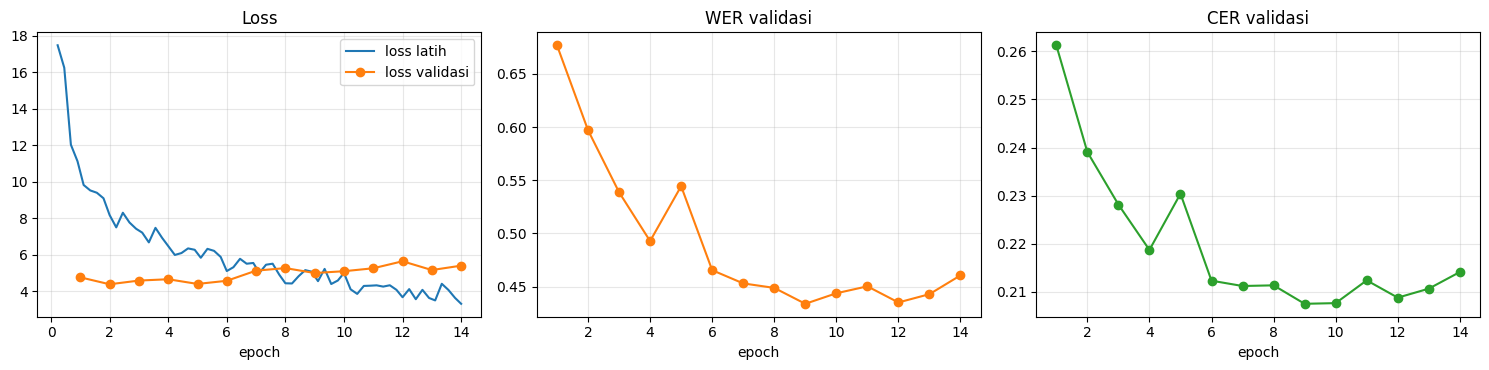

In [14]:
history = history_frame(trainer)
plot_history(history).show()
ev = history[history["eval_wer"].notna()]
print(ev[["epoch", "eval_loss", "eval_wer", "eval_cer"]].round(4).to_string(index=False))
print("checkpoint WER terbaik:", trainer.state.best_model_checkpoint, "| eval_wer:", trainer.state.best_metric)
print("model CER terbaik:", best_cer_saver.best)

Kedua kandidat dievaluasi ulang pada seluruh validation set (442 ujaran) dengan greedy decoding. Metrik utama adalah WER/CER ketat, yaitu é harus tepat. Versi folded menganggap é sama dengan e, angkanya lebih rendah karena penilaiannya lebih longgar, bukan karena modelnya lebih baik.

| Model | WER | CER | WER folded | CER folded | Akurasi kata é |
|---|---|---|---|---|---|
| Baseline (zero-shot) | 0,673 | 0,276 | 0,632 | 0,262 | 0% |
| Fine-tuned (epoch 9) | 0,444 | 0,209 | 0,437 | 0,206 | 55,5% (253/456) |

Fine-tuning menurunkan WER sebesar 22,8 poin dan CER sebesar 6,7 poin. Model sekarang menulis 454 huruf é (referensi: 499). Kesalahan kata didominasi substitusi (1499 dari 2109).

WER hasil evaluasi ulang ini (0,444) sedikit lebih tinggi daripada WER yang dicatat Trainer pada epoch yang sama (0,434). Angka yang kami laporkan adalah hasil evaluasi ulang.

In [15]:
# Model WER terbaik sudah dimuat kembali oleh Trainer (load_best_model_at_end)
trainer.model.save_pretrained(os.path.join(RUN_DIR, "best_wer", "model"))
refs = val.transcription_normalized.tolist()
candidates = {"wer": {"path": os.path.join(RUN_DIR, "best_wer", "model"),
                      "epoch": float(ev.loc[ev.eval_wer.idxmin(), "epoch"])},
              "cer": {"path": os.path.join(RUN_DIR, "best_cer", "model"),
                      "epoch": float(best_cer_saver.best["epoch"])}}
best_wer_checkpoint = trainer.state.best_model_checkpoint
del trainer
gc.collect()
torch.cuda.empty_cache()

for name, c in candidates.items():
    m = Wav2Vec2ForCTC.from_pretrained(c["path"]).to(DEVICE)
    c["preds"] = transcribe_files(m, processor, val.abs_audio_path.tolist(), batch_size=4, device=DEVICE)
    c["metrics"] = evaluate_predictions(refs, c["preds"])
    del m
    torch.cuda.empty_cache()

# Baseline zero-shot Cahya dari notebook 01 pada pembagian validasi 21 penutur
BASELINE = {"wer": 0.6728, "cer": 0.2760, "wer_folded": 0.6319, "cer_folded": 0.2620}
assert meta["manifest_fingerprint"].startswith("c3abac0a"), "pembagian data berubah: perbarui angka BASELINE dari notebook 01"
columns = ["wer", "cer", "wer_folded", "cer_folded", "e_word_accuracy", "e_chars_predicted"]
rows = [{"model": "baseline (zero-shot)", **BASELINE}]
rows += [{"model": f"{n.upper()} terbaik", "epoch": c["epoch"], **{k: c["metrics"][k] for k in columns}}
         for n, c in candidates.items()]
comparison = pd.DataFrame(rows)
comparison.to_csv(os.path.join(RUN_DIR, "model_comparison.csv"), index=False)
print(comparison.round(4).to_string(index=False))
# Hasil kedua model disimpan agar pilihan dapat dibuat setelah sesi selesai tanpa melatih ulang
pd.DataFrame({"file": val.file, "speaker_id": val.speaker_id, "reference": refs,
              **{f"prediction_best_{n}": c["preds"] for n, c in candidates.items()}}
             ).to_csv(os.path.join(RUN_DIR, "candidate_predictions.csv"), index=False)
with open(os.path.join(RUN_DIR, "candidate_metrics.json"), "w", encoding="utf-8") as f:
    json.dump({n: {"epoch": c["epoch"], **c["metrics"]} for n, c in candidates.items()}, f, indent=2)
if candidates["wer"]["epoch"] == candidates["cer"]["epoch"]:
    print("Kedua model berasal dari epoch yang sama, jadi tidak ada yang perlu dipilih.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

               model    wer    cer  wer_folded  cer_folded  epoch  e_word_accuracy  e_chars_predicted
baseline (zero-shot) 0.6728 0.2760      0.6319      0.2620    NaN              NaN                NaN
         WER terbaik 0.4444 0.2094      0.4366      0.2062    9.0           0.5548              454.0
         CER terbaik 0.4444 0.2094      0.4366      0.2062    9.0           0.5548              454.0
Kedua model berasal dari epoch yang sama, jadi tidak ada yang perlu dipilih.


### Final Model Selection
Pilihan dibuat hanya dari hasil validation di atas, sebelum model apa pun dievaluasi pada test set. Kedua kandidat (`best_wer/` dan `best_cer/`) disimpan beserta prediksi dan metriknya (`candidate_predictions.csv`, `candidate_metrics.json`). Folder `model/` dan `validation_metrics.json` mengikuti `FINAL_CHOICE`.

**Pilihan:** `FINAL_CHOICE = "wer"`. Kandidat WER terbaik dan CER terbaik sama-sama berasal dari epoch 9, jadi keduanya model yang sama dan pilihan ini tidak mengubah hasil.

In [16]:
FINAL_CHOICE = "wer"  # "wer" atau "cer"
chosen = candidates[FINAL_CHOICE]
preds, result = chosen["preds"], chosen["metrics"]
metrics = {"model_id": MODEL_ID, "split": "val", "final_choice": FINAL_CHOICE, "epoch": chosen["epoch"],
           **result, "baseline": BASELINE}
print(f"model {FINAL_CHOICE.upper()} terbaik (epoch {chosen['epoch']:g})")
print(f"ketat      : WER {result['wer']:.4f} (baseline {BASELINE['wer']:.4f}) | CER {result['cer']:.4f} (baseline {BASELINE['cer']:.4f})")
print(f"tanpa aksen: WER {result['wer_folded']:.4f} (baseline {BASELINE['wer_folded']:.4f}) | CER {result['cer_folded']:.4f} (baseline {BASELINE['cer_folded']:.4f})")
print(f"kata ber-é benar: {result['e_words_correct']}/{result['e_words_total']} | huruf é diprediksi: {result['e_chars_predicted']} (referensi {result['e_chars_reference']})")
if result["e_chars_predicted"] == 0:
    print("PERINGATAN: model tidak pernah menulis é, token baru tidak terpelajari.")

model WER terbaik (epoch 9)
ketat      : WER 0.4444 (baseline 0.6728) | CER 0.2094 (baseline 0.2760)
tanpa aksen: WER 0.4366 (baseline 0.6319) | CER 0.2062 (baseline 0.2620)
kata ber-é benar: 253/456 | huruf é diprediksi: 454 (referensi 499)


## I. Artifact Saving
Model, processor, konfigurasi, riwayat training, prediksi, dan metrik disimpan di `RUN_DIR`.

In [17]:
cfg_record = {"model_id": MODEL_ID, "model_revision": model_revision(MODEL_ID), "seed": SEED,
              "training": cfg["training"], "vocab_extended_with": vocab_extended,
              "tokenizer": {k: v for k, v in audit.items() if k != "missing_target_chars"},
              "normalization_version": meta["normalization_version"], "decoding": "greedy CTC",
              "best_lr": BEST_LR, "sweep_results": sweep_results.to_dict("records"),
              "final_choice": FINAL_CHOICE, "best_wer_checkpoint": best_wer_checkpoint, "best_cer": best_cer_saver.best,
              "drift_from_cahya": ["D1 checkpoint awal", "D2 é dipertahankan", "D3 LR diuji", "D7 warmup 10%",
                                   "D13 pemilihan model dan early stopping", "D14 evaluasi per epoch",
                                   "D15 normalisasi v1", "D18 WER/CER ketat dan tanpa aksen",
                                   "D20 pembagian per penutur"],
              "split": {"manifest_fingerprint": meta["manifest_fingerprint"], "seed": meta["seed"],
                        "train_speakers": meta["subsets"]["train"]["speakers"], "val_speakers": meta["subsets"]["val"]["speakers"]},
              "n_train": len(train), "n_val": len(val), "env": env_info(), "resumed_from": checkpoint}
final_model = Wav2Vec2ForCTC.from_pretrained(chosen["path"])
save_artifacts(final_model, history, processor, RUN_DIR, cfg_record, val, preds, metrics)
del final_model
for root, _, files in os.walk(RUN_DIR):
    if "checkpoints" not in root and "sweep" not in root:
        print(root.replace(RUN_DIR, RUN_NAME), files)

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

cahya_finetuned ['model_comparison.csv', 'training_config.json', 'validation_metrics.json', 'candidate_predictions.csv', 'training_history.csv', 'candidate_metrics.json', 'validation_predictions.csv', 'sweep_results.csv']
cahya_finetuned/best_cer ['best.json']
cahya_finetuned/best_cer/model ['config.json', 'model.safetensors']
cahya_finetuned/model ['config.json', 'model.safetensors']
cahya_finetuned/best_wer []
cahya_finetuned/best_wer/model ['config.json', 'model.safetensors']
cahya_finetuned/processor ['vocab.json', 'tokenizer_config.json', 'added_tokens.json', 'processor_config.json']


## J. Inference Sanity Check
Model dan processor yang tersimpan dimuat ulang dari disk, lalu dipakai mentranskripsi beberapa ujaran validation.

In [18]:
torch.cuda.empty_cache()
reloaded_model = Wav2Vec2ForCTC.from_pretrained(os.path.join(RUN_DIR, "model")).to(DEVICE)
reloaded_processor = Wav2Vec2Processor.from_pretrained(os.path.join(RUN_DIR, "processor"))
sample = val.iloc[:5]
# Susunan batch harus sama dengan saat evaluasi karena padding yang berbeda dapat mengubah keluaran model
reloaded_preds = transcribe_files(reloaded_model, reloaded_processor, val.abs_audio_path.tolist(), batch_size=4, device=DEVICE)[:5]
assert reloaded_preds == preds[:5], "model termuat ulang menghasilkan prediksi berbeda dari model di memori"
for file, ref, hyp in zip(sample.file, sample.transcription_normalized, reloaded_preds):
    print(f"{file}\n  REF: {ref}\n  HIP: {hyp}")

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

G04_S05_T01_001.WAV
  REF: nami abdi mayla yaffa ludmilla tiasa disaur lala
  HIP: nami abdi mayan laya kaleuk mila biasa disaur lala
G04_S05_T01_002.WAV
  REF: umur abdi dua puluh taun sareng ayeuna abdi mahasiswa jurusan teknik informatika di institut teknologi bandung
  HIP: umura abdi dua puluh taun sareng ayeuna abdi mahasiswa jorusan teknik informatika di institut téknologi bandung
G04_S05_T01_003.WAV
  REF: atanapi itb abdi parantos cicing di bandung ti saprak lahir
  HIP: atanapi it babdi parantos ticing di bandung ti saprak lahir
G04_S05_T01_004.WAV
  REF: tapi sabenerna abdi sanés urang sunda
  HIP: tapi sabenerna abdi sanes urang sunda kadu reser puh abdi asalna ti sumatra
G04_S05_T01_005.WAV
  REF: kulawarga abdi masih sok mulang ka lampung unggal taun
  HIP: kaluwarga abdi masih sok mulang ka lampung ungal taun
